# 재활용 쓰레기 YOLO11s Instance Segmentation · Orin Nano

**출력: 물체별 마스크 + PAPER/CAN/PET/VINYL 종류 + confidence.** 하나의 seg 모델이 영역과 종류를 동시에 예측합니다.
이는 재질·품목 분류이며 실제 재활용 가능 여부(오염, 복합재, 지역 규정)를 확정하는 모델이 아닙니다.
4종 밖의 물체를 모두 OTHER로 알아보지는 않습니다.

순서: GPU 선택 → 설치 → SEG ZIP 경로 → 라벨 검사 함수 → EXIF 검토 → 병합 → 정답 마스크 검토 → 학습 → 평가 → 예측 → 내보내기.
원본 파일과 데이터는 수정하지 않습니다. 실행 출력과 개인/위젯 메타데이터는 제거했습니다.

In [ ]:
import sys, subprocess
# 원본 실행 로그의 버전으로 고정. 새 버전 사용 시 아래 버전을 변경하고 재검증하세요.
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'ultralytics==8.4.131', 'pyyaml', 'pandas', 'pillow', 'matplotlib', 'ipywidgets', 'shapely'])
try:
    import google.colab
    colab = True
except ImportError:
    colab = False
if colab:
    from google.colab import drive
    drive.mount('/content/drive')
from pathlib import Path
import shutil, zipfile, hashlib, json, math, random
import numpy as np
from collections import Counter
from datetime import datetime
import yaml, torch, ultralytics, pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display
from ultralytics import YOLO
print('Ultralytics:', ultralytics.__version__, '| GPU:', torch.cuda.is_available())

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics: 8.4.131 | GPU: True


## 1. 설정

In [ ]:
CLASSES = ['PAPER', 'CAN', 'PET', 'VINYL']
if colab:
    OLD_DATASET_ZIP = '/content/drive/MyDrive/ai/final/model_seg/dataset_polygon.zip'
    NEW_DATASET_ZIP = ''  # 선택: .../specific_data2_seg.zip
    WORK_ROOT = Path('/content/recycle_seg_work')
    SAVE_ROOT = Path('/content/drive/MyDrive/ai/final/model_seg/runs_seg')
else:
    OLD_DATASET_ZIP = './dataset_seg.zip'
    NEW_DATASET_ZIP = ''
    WORK_ROOT = Path('./recycle_seg_work').resolve()
    SAVE_ROOT = Path('./save/recycle_seg').resolve()
SOURCES = [('old', OLD_DATASET_ZIP)]
if NEW_DATASET_ZIP.strip(): SOURCES.append(('new', NEW_DATASET_ZIP))
MODEL = 'yolo11s-seg.pt'
IMGSZ, BATCH, EPOCHS = 832, 8, 200
DEPLOY_IMGSZ = 640
SEED = 42
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
ALLOW_CPU_TRAIN = False
INFER_CONF = 0.25  # 출발값. val로 조정하고 test에는 고정
EXPORT_ONNX = True

## 2. Polygon 라벨 검증
한 줄 = 한 객체: `class x1 y1 x2 y2 ...`. 좌표는 0~1, 점 3개 이상, 면적이 있고 자기 교차가 없어야 합니다.
빈 TXT는 목표 클래스가 없는 배경입니다. TXT 누락은 오류입니다. 구멍과 여러 분리 영역은 단일 polygon TXT로 정확하게 표현하기 어려우므로 별도 라벨 정책과 내보내기 검토가 필요합니다.

In [ ]:
from shapely.geometry import Polygon

def read_segments(path, mapping):
    segments=[]
    for n, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):
        if not line.strip(): continue
        v = list(map(float, line.split()))
        if len(v) == 5:
            raise ValueError(f'detection 박스 라벨입니다. polygon 재라벨링 필요: {path}:{n}')
        if len(v) < 7 or (len(v)-1) % 2 or not all(math.isfinite(x) for x in v):
            raise ValueError(f'seg 좌표 형식 오류: {path}:{n}')
        c, coords = v[0], v[1:]
        if not c.is_integer() or int(c) not in mapping:
            raise ValueError(f'클래스 ID 오류: {path}:{n}')
        if any(x < 0 or x > 1 for x in coords):
            raise ValueError(f'정규화 좌표 범위 오류: {path}:{n}')
        points = list(zip(coords[::2], coords[1::2]))
        if points[-1] == points[0]: points.pop()
        poly = Polygon(points) if len(set(points)) >= 3 else None
        if poly is None or not poly.is_valid or poly.area <= 1e-10:
            raise ValueError(f'퇴화/자기교차 polygon: {path}:{n}')
        # 시작 꼭짓점 및 순방향 차이 정규화: 중복 비교에 사용
        variants=[]
        for ring in (points, list(reversed(points))):
            k=min(range(len(ring)), key=lambda i:ring[i])
            variants.append(tuple(ring[k:]+ring[:k]))
        flat=tuple(x for point in min(variants) for x in point)
        item=(mapping[int(c)], *flat)
        if item in segments:
            raise ValueError(f'동일 객체 라벨 중복: {path}:{n}')
        segments.append(item)
    return sorted(segments)

def draw_segments(canvas, segments):
    draw=ImageDraw.Draw(canvas, 'RGBA')
    palette=[(255,70,70), (30,190,255), (70,220,100), (220,100,255), (255,190,40)]
    for c,*coords in segments:
        points=[(x*canvas.width,y*canvas.height) for x,y in zip(coords[::2],coords[1::2])]
        color=palette[c % len(palette)]
        draw.polygon(points, fill=(*color,65), outline=(*color,255), width=max(2,canvas.width//250))
        draw.text(points[0], f'{c}: {CLASSES[c] if c<len(CLASSES) else c}', fill=(255,255,255,255))
    return canvas

## 3. EXIF 방향 검토

In [ ]:
from PIL import ImageOps
import io
import ipywidgets as widgets

EXIF_REVIEW_DIR = SAVE_ROOT / 'exif_review_seg'
EXIF_REVIEW_DIR.mkdir(parents=True, exist_ok=True)
EXIF_CHOICES_PATH = EXIF_REVIEW_DIR / 'choices.json'
EXIF_CHOICES = json.loads(EXIF_CHOICES_PATH.read_text(encoding='utf-8')) if EXIF_CHOICES_PATH.exists() else {}
EXIF_ITEMS = []
REVIEW_EXTS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}

def exif_key(tag, image_bytes, label_bytes):
    # 이미지 또는 라벨이 바뀌면 이전 선택을 재사용하지 않음
    return tag + ':' + hashlib.sha256(image_bytes).hexdigest() + ':' + hashlib.sha256(label_bytes).hexdigest()

def exif_rgb(im, choice):
    if choice == 'A':
        return im.convert('RGB')
    if choice == 'B':
        return ImageOps.exif_transpose(im).convert('RGB')
    raise ValueError('EXIF A/B 선택 필요')

for tag, zp in SOURCES:
    if not zp or not Path(zp).is_file():
        raise FileNotFoundError(f'{tag} ZIP 경로 확인: {zp}')
    with zipfile.ZipFile(zp) as z:
        names=set(z.namelist())
        for member in sorted(names):
            if Path(member).suffix.lower() not in REVIEW_EXTS: continue
            image_bytes=z.read(member)
            with Image.open(io.BytesIO(image_bytes)) as im:
                orientation=im.getexif().get(274,1)
                if orientation == 1: continue
            parts=list(Path(member).with_suffix('.txt').parts)
            candidates=[Path(*parts).as_posix()]
            if 'images' in parts:
                parts[parts.index('images')]='labels'
                candidates.append(Path(*parts).as_posix())
            labels=[n for n in dict.fromkeys(candidates) if n in names]
            if len(labels)!=1:
                raise ValueError(f'EXIF 검토용 TXT를 하나로 찾지 못했습니다: {member}, {labels}')
            label_bytes=z.read(labels[0])
            key=exif_key(tag,image_bytes,label_bytes)
            EXIF_ITEMS.append(dict(key=key,source=tag,zip=str(zp),member=member,label=labels[0],orientation=orientation))

def save_exif_choice(key, value):
    EXIF_CHOICES[key]=value
    tmp=EXIF_CHOICES_PATH.with_suffix('.tmp')
    tmp.write_text(json.dumps(EXIF_CHOICES,ensure_ascii=False,indent=2),encoding='utf-8')
    tmp.replace(EXIF_CHOICES_PATH)

def require_exif_review():
    pending=[r['member'] for r in EXIF_ITEMS if EXIF_CHOICES.get(r['key']) not in ('A','B','SKIP')]
    if pending:
        raise ValueError(f'EXIF 미확인 {len(pending)}장. 위 검토 셀에서 모두 선택한 뒤 병합 셀 재실행: {pending[:5]}')

def show_exif_page(page=1):
    start=(int(page)-1)*6
    for item in EXIF_ITEMS[start:start+6]:
        with zipfile.ZipFile(item['zip']) as z:
            image_bytes=z.read(item['member'])
            label_text=z.read(item['label']).decode('utf-8-sig')
        print(item['source'], item['member'], '| EXIF:',item['orientation'])
        panels=[]
        for choice in ['A','B']:
            with Image.open(io.BytesIO(image_bytes)) as im:
                canvas=exif_rgb(im,choice)
            draw=ImageDraw.Draw(canvas)
            W,H=canvas.size
            for line in label_text.splitlines():
                if not line.strip(): continue
                values=list(map(float,line.split()))
                if len(values)<7 or (len(values)-1)%2:
                    raise ValueError(f"seg polygon 필요: {item['label']}")
                cid,*coords=values
                points=[(x*W,y*H) for x,y in zip(coords[::2],coords[1::2])]
                draw.polygon(points,outline='red',width=max(2,W//200))
                draw.text(points[0],f'ID {int(cid)}',fill='red')
            canvas.thumbnail((480,480))
            panel=Image.new('RGB',(500,520),'white')
            panel.paste(canvas,(10,30))
            ImageDraw.Draw(panel).text((10,10),choice,fill='black')
            panels.append(panel)
        pair=Image.new('RGB',(1000,520),'white')
        pair.paste(panels[0],(0,0)); pair.paste(panels[1],(500,0))
        display(pair)
        dropdown=widgets.Dropdown(
            options=[('미확인',''),('A: 원본 픽셀에 polygon가 맞음','A'),
                     ('B: EXIF 회전 후 polygon가 맞음','B'),('둘 다 틀림/판단 불가: 이번 학습에서 제외','SKIP')],
            value=EXIF_CHOICES.get(item['key'],''),layout=widgets.Layout(width='550px'))
        status=widgets.Label()
        def changed(change,key=item['key'],status=status):
            if change['name']=='value':
                save_exif_choice(key,change['new'])
                status.value='저장됨: '+(change['new'] or '미확인')
        dropdown.observe(changed,names='value')
        display(dropdown,status)
    print('선택은 Drive에 자동 저장됩니다. 모든 페이지 확인 후 아래 병합 셀을 실행하세요.')

print('EXIF 확인 대상:',len(EXIF_ITEMS),'장 | 저장:',EXIF_CHOICES_PATH)
print('A/B 모두 polygon가 맞으면 물체 방향과 실제 라벨링 화면을 함께 확인하세요. 판단 불가이면 제외하세요.')
if EXIF_ITEMS:
    display(widgets.interactive(show_exif_page,page=widgets.IntSlider(
        value=1,min=1,max=(len(EXIF_ITEMS)+5)//6,description='페이지',continuous_update=False)))
else:
    print('EXIF 검토 대상 없음. 병합 셀로 진행하세요.')

EXIF 확인 대상: 0 장 | 저장: /content/drive/MyDrive/ai/final/model_seg/runs_seg/exif_review_seg/choices.json
A/B 모두 polygon가 맞으면 물체 방향과 실제 라벨링 화면을 함께 확인하세요. 판단 불가이면 제외하세요.
EXIF 검토 대상 없음. 병합 셀로 진행하세요.


## 4. ZIP 병합 · 누수 검사 · 데이터 통계


In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
def split_folders(root, split):
    names = ['val', 'valid'] if split == 'val' else [split]
    found = []
    for name in names:
        for im, lb in [(root/name/'images', root/name/'labels'),
                       (root/'images'/name, root/'labels'/name)]:
            if im.is_dir(): found.append((im, lb))
    # split 폴더에 이미지와 TXT가 함께 있는 ZIP도 지원
    for name in names:
        folder = root / name
        if folder.is_dir() and any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTS
            for p in folder.iterdir()
        ):
            found.append((folder, folder))
    if len(found) > 1: raise ValueError(f'분할 경로 중복: {root}, {split}')
    if found and not found[0][1].is_dir(): raise ValueError(f'labels 없음: {found}')
    return found[0] if found else None

def index_files(folder, exts):
    result = {}
    for p in sorted(folder.rglob('*')):
        if p.is_file() and p.suffix.lower() in exts:
            key = p.relative_to(folder).with_suffix('').as_posix()
            if key in result: raise ValueError(f'동일 stem 중복: {p}')
            result[key] = p
    return result

def merge_datasets(sources, work_root):
    require_exif_review()
    for tag, zp in sources:
        if not zp or not Path(zp).is_file():
            raise FileNotFoundError(f'{tag} ZIP 실제 경로를 설정하세요: {zp!r}')
    run_id = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    merged = work_root / run_id / 'merged'
    merged.mkdir(parents=True, exist_ok=False)
    records, duplicates, seen = [], [], {}
    for tag, zp in sources:
        target = merged.parent / ('extracted_' + tag)
        target.mkdir()
        with zipfile.ZipFile(zp) as z:
            for item in z.infolist():
                if not (target/item.filename).resolve().is_relative_to(target.resolve()):
                    raise ValueError(f'잘못된 ZIP 경로: {item.filename}')
                if (item.external_attr >> 16) & 0o170000 == 0o120000:
                    raise ValueError('ZIP symlink는 지원하지 않습니다.')
            z.extractall(target)
        candidates = [p for p in [target, *target.rglob('*')] if p.is_dir()
                      and any((p/n).is_file() for n in ('data.yaml','data.yml'))
                      and split_folders(p, 'train') and split_folders(p, 'val')]
        if len(candidates) != 1: raise ValueError(f'{tag}: 데이터 루트 확인: {candidates}')
        root = candidates[0]
        yamls = [root/n for n in ['data.yaml', 'data.yml'] if (root/n).is_file()]
        if len(yamls) != 1: raise ValueError(f'{tag}: data.yaml 하나가 필요합니다.')
        names = yaml.safe_load(yamls[0].read_text(encoding='utf-8-sig'))['names']
        if isinstance(names, list): names = dict(enumerate(names))
        names = {int(k): str(v).strip().upper() for k,v in names.items()}
        if set(names.values()) != set(CLASSES) or len(names) != len(CLASSES):
            raise ValueError(f'{tag}: CLASSES와 YAML 클래스가 일치하는지 확인: {names}')
        mapping = {k: CLASSES.index(v) for k,v in names.items()}
        print(tag, '원본 클래스:', names, '→', mapping)
        for split in ['train', 'val', 'test']:
            folders = split_folders(root, split)
            if folders is None: continue
            ims, lbs = index_files(folders[0], IMAGE_EXTS), index_files(folders[1], {'.txt'})
            if not ims: raise ValueError(f'{tag}/{split}: 이미지가 없습니다.')
            if ims.keys() != lbs.keys():
                raise ValueError(f'{tag}/{split}: 짝 불일치: {list(ims.keys() ^ lbs.keys())[:20]}')
            for key, p in ims.items():
                segments = read_segments(lbs[key], mapping)
                with Image.open(p) as im:
                    im.load()
                    strip_orientation = im.getexif().get(274, 1) != 1
                    choice = 'NONE'
                    if strip_orientation:
                        review_id = exif_key(tag, p.read_bytes(), lbs[key].read_bytes())
                        choice = EXIF_CHOICES.get(review_id)
                        if choice == 'SKIP':
                            duplicates.append(dict(source=tag,split=split,original=str(p),reason='EXIF review: excluded'))
                            continue
                        if choice not in ('A','B'):
                            raise ValueError(f'이 파일의 EXIF 선택 필요. 검토 셀 재실행: {p}')
                        rgb = exif_rgb(im, choice)
                    else:
                        rgb = im.convert('RGB')
                    digest = hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
                    if digest in seen:
                        prev=seen[digest]
                        if prev['split'] != split:
                            raise ValueError(f"분할 간 동일 이미지: {p} / {prev['original']}")
                        if prev['segments'] != segments:
                            raise ValueError(f"동일 이미지 polygon 충돌: {p} / {prev['original']}")
                        duplicates.append(dict(source=tag,split=split,original=str(p),kept=prev['image'],reason='동일 이미지/라벨'))
                        continue
                dest = merged/'images'/split/tag/(key+('.png' if strip_orientation else p.suffix.lower()))
                label = merged/'labels'/split/tag/(key+'.txt')
                dest.parent.mkdir(parents=True, exist_ok=True)
                label.parent.mkdir(parents=True, exist_ok=True)
                if strip_orientation:
                    # 선택한 방향의 픽셀을 PNG로 저장, EXIF 전달 방지.
                    clean = Image.frombytes('RGB', rgb.size, rgb.tobytes())
                    clean.save(dest, format='PNG')
                else:
                    shutil.copy2(p, dest)
                label.write_text(''.join(str(row[0])+' '+ ' '.join(f'{x:.12g}' for x in row[1:])+'\n' for row in segments), encoding='utf-8')
                rec=dict(source=tag, split=split, original=str(p), image=str(dest),
                         segments=segments, sha256=digest, width=rgb.width, height=rgb.height, exif_choice=choice)
                records.append(rec)
                seen[digest] = rec
    for split in ('train', 'val'):
        present={s[0] for r in records if r['split']==split for s in r['segments']}
        if present != set(range(len(CLASSES))):
            raise ValueError(f'{split}: 클래스별 객체가 필요합니다. 존재 ID={present}')
    cfg=dict(path=merged.as_posix(), train='images/train', val='images/val', names=CLASSES, nc=len(CLASSES))
    if any(r['split']=='test' for r in records): cfg['test']='images/test'
    data=merged/'data.yaml'
    data.write_text(yaml.safe_dump(cfg, sort_keys=False), encoding='utf-8')
    (merged/'manifest.json').write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding='utf-8')
    pd.DataFrame(duplicates).to_csv(merged/'duplicates_removed.csv', index=False)
    return run_id, merged, data, records

RUN_ID, DATASET_ROOT, DATA, records = merge_datasets(SOURCES, WORK_ROOT)
samples = {s: [(Path(r['image']),r['segments']) for r in records if r['split']==s] for s in ['train','val','test']}
summary_rows=[]
for tag,_ in SOURCES:
    for split in ['train','val','test']:
        rr=[r for r in records if r['source']==tag and r['split']==split]
        counts=Counter(CLASSES[b[0]] for r in rr for b in r['segments'])
        summary_rows.append(dict(source=tag, split=split, images=len(rr), backgrounds=sum(not r['segments'] for r in rr), **{c:counts[c] for c in CLASSES}))
summary=pd.DataFrame(summary_rows)
display(summary)
summary.to_csv(DATASET_ROOT/'dataset_counts.csv', index=False)
for split in ['train','val']:
    present={b[0] for r in records if r['split']==split for b in r['segments']}
    if present != set(range(len(CLASSES))): raise ValueError(f'{split}: 일부 클래스의 박스가 없습니다: {present}')
print('통합 YAML:', DATA)

old 원본 클래스: {0: 'PAPER', 1: 'CAN', 2: 'PET', 3: 'VINYL'} → {0: 0, 1: 1, 2: 2, 3: 3}


,source,split,images,backgrounds,PAPER,CAN,PET,VINYL
0,old,train,1462,0,401,400,316,345
1,old,val,359,0,100,100,73,86
2,old,test,0,0,0,0,0,0


통합 YAML: /content/recycle_seg_work/20260913_221430_265648/merged/data.yaml


## 5. 정답 마스크 검토
윤곽이 배경/그림자를 포함하는지, 투명 물체 외곽과 겹침이 맞는지 확인하세요.

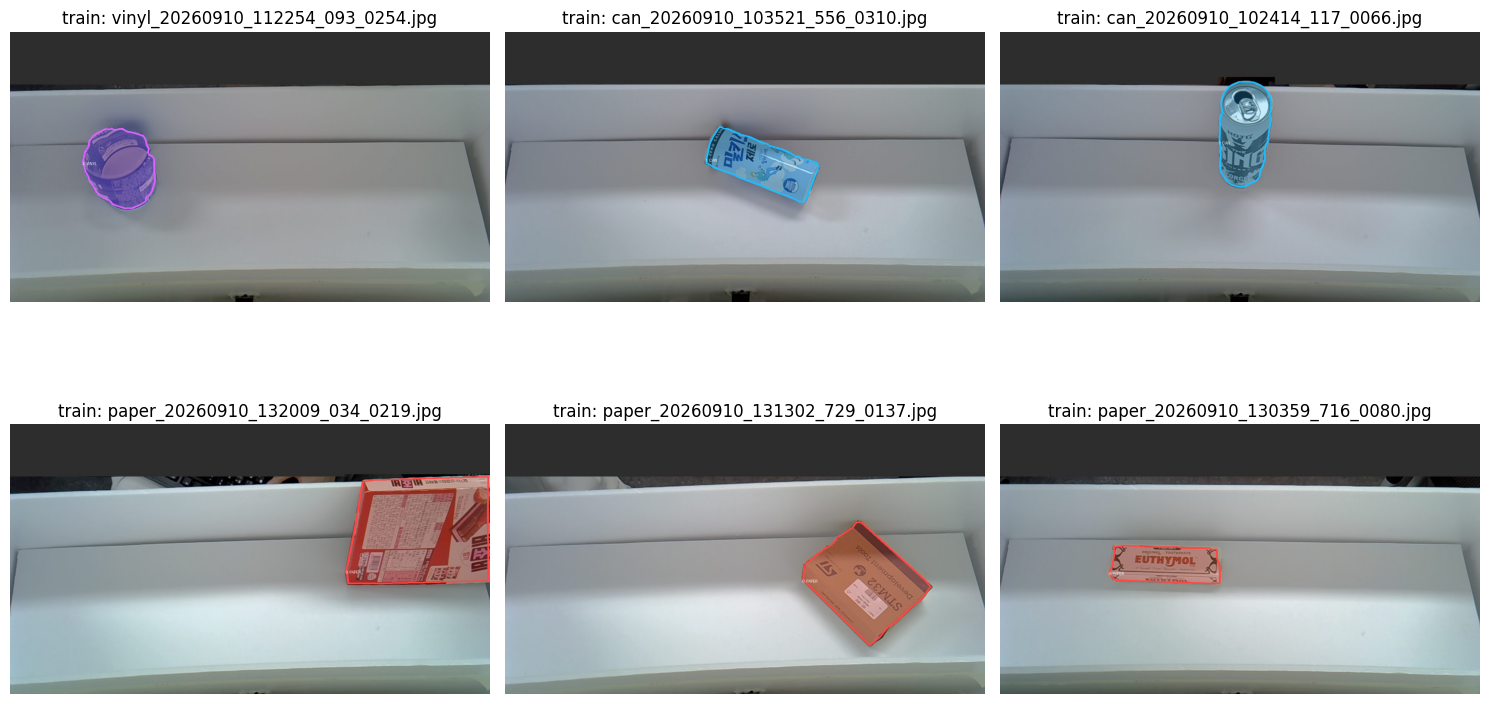

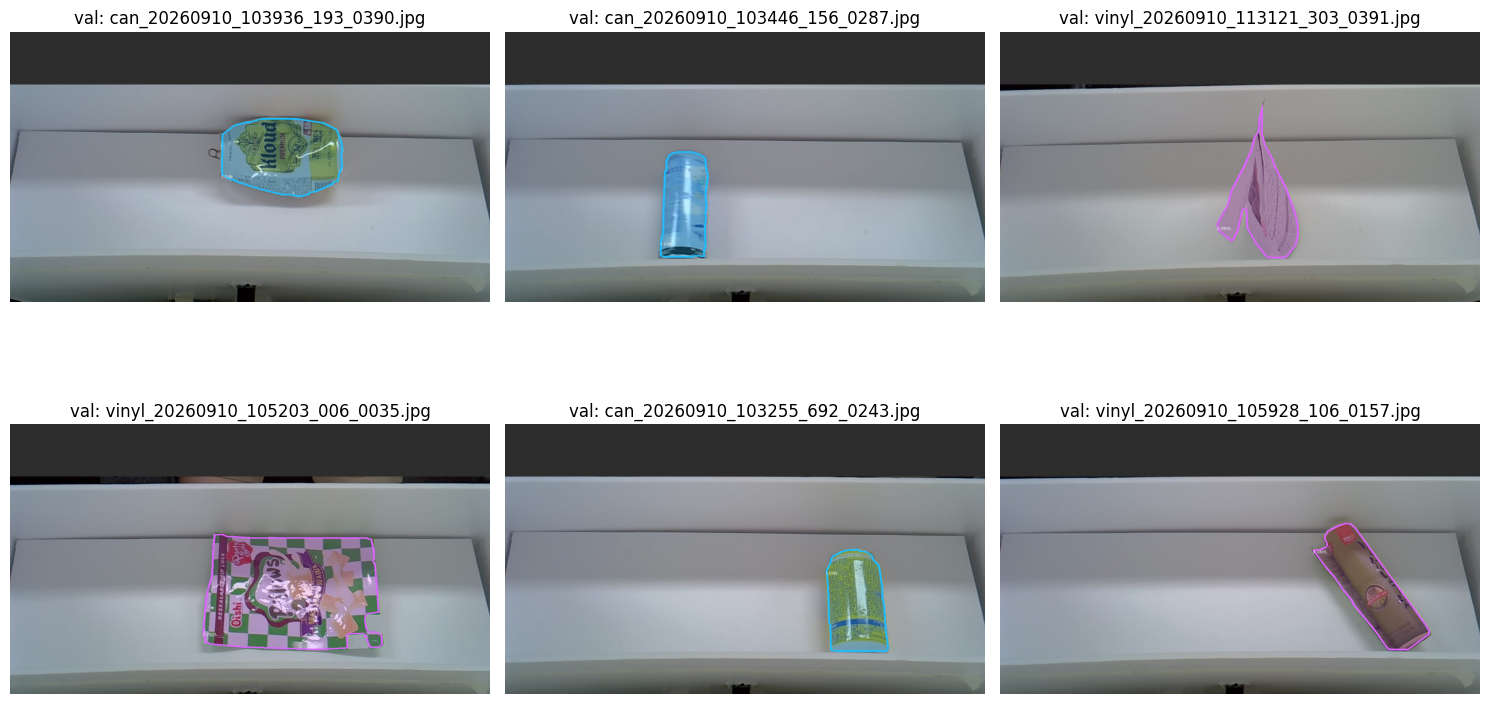

In [ ]:
import matplotlib.pyplot as plt
rng=random.Random(SEED)
for split in ('train','val'):
    selected=rng.sample(samples[split], min(6,len(samples[split])))
    fig,axes=plt.subplots(2,3,figsize=(15,9))
    for ax in axes.flat: ax.axis('off')
    for ax,(p,segments) in zip(axes.flat,selected):
        with Image.open(p) as im: canvas=draw_segments(im.convert('RGB'),segments)
        ax.imshow(canvas); ax.set_title(f'{split}: {p.name}')
    plt.tight_layout(); plt.show()

## 6. 학습


In [ ]:
if DEVICE == 'cpu' and not ALLOW_CPU_TRAIN:
    raise RuntimeError('GPU 런타임을 선택하세요. CPU 실행을 원하면 ALLOW_CPU_TRAIN=True.')
SAVE_ROOT.mkdir(parents=True, exist_ok=True)
yolo = YOLO(MODEL, task='segment')
assert yolo.task == 'segment'
train_args = dict(data=str(DATA), epochs=EPOCHS, patience=30, imgsz=IMGSZ,
    batch=BATCH, device=DEVICE, workers=2 if colab else 0,
    project=str(SAVE_ROOT), name=f'recycle_{Path(MODEL).stem}_{RUN_ID}',
    optimizer='AdamW', lr0=0.001, lrf=0.01, weight_decay=0.0005,
    cos_lr=True, warmup_epochs=3.0, seed=SEED, deterministic=True,
    amp=DEVICE != 'cpu', cache=False, degrees=45.0, translate=0.1, scale=0.5,
    shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.5,
    hsv_h=0.01, hsv_s=0.3, hsv_v=0.25,
    mosaic=0.5, close_mosaic=20, mixup=0.0, copy_paste=0.0,
    mask_ratio=4, overlap_mask=True, val=True, plots=True, save=True, save_period=10, exist_ok=False)
train_results = yolo.train(**train_args)
RUN_DIR = Path(yolo.trainer.save_dir)
BEST = RUN_DIR/'weights'/'best.pt'
assert BEST.is_file(), f'best.pt가 없습니다: {RUN_DIR}'
print('학습 완료:', BEST)

New https://pypi.org/project/ultralytics/8.4.150 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/recycle_seg_work/20260913_221430_265648/merged/data.yaml, degrees=45.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.25, imgsz=832, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio

## 7. 평가


In [ ]:
yolo_best=YOLO(str(BEST), task='segment')
assert yolo_best.task == 'segment'
REPORT_DIR=RUN_DIR/'reports_seg'
REPORT_DIR.mkdir(exist_ok=True)
overall, per_class=[],[]
for split in ('val','test'):
    subset=[r for r in records if r['split']==split]
    if not subset:
        print(f'{split}: 데이터 없음. 독립 최종 성능으로 주장하지 마세요.'); continue
    for source in ['all']+sorted({r['source'] for r in subset}):
        rr=subset if source=='all' else [r for r in subset if r['source']==source]
        image_list=REPORT_DIR/f'{split}_{source}_images.txt'
        image_list.write_text('\n'.join(r['image'] for r in rr)+'\n',encoding='utf-8')
        cfg=yaml.safe_load(DATA.read_text(encoding='utf-8'))
        cfg[split]=str(image_list.resolve())
        eval_yaml=REPORT_DIR/f'{split}_{source}.yaml'
        eval_yaml.write_text(yaml.safe_dump(cfg,sort_keys=False),encoding='utf-8')
        metrics=yolo_best.val(data=str(eval_yaml),split=split,imgsz=DEPLOY_IMGSZ,
            batch=1,device=DEVICE,conf=0.001,iou=0.7,plots=True,
            project=str(REPORT_DIR),name=f'eval_{split}_{source}')
        overall.append(dict(split=split,source=source,images=len(rr),
            box_mAP50=float(metrics.box.map50),box_mAP50_95=float(metrics.box.map),
            mask_mAP50=float(metrics.seg.map50),mask_mAP50_95=float(metrics.seg.map)))
        counts=Counter(s[0] for r in rr for s in r['segments'])
        for cid,name in enumerate(CLASSES):
            row=dict(split=split,source=source,class_name=name,instances=counts[cid])
            for kind,metric in [('box',metrics.box),('mask',metrics.seg)]:
                ids=[int(x) for x in metric.ap_class_index]
                values=metric.class_result(ids.index(cid)) if cid in ids else [float('nan')]*4
                row.update({kind+'_'+k:float(v) for k,v in zip(['P','R','mAP50','mAP50_95'],values)})
            per_class.append(row)
for name,rows in [('overall',overall),('per_class',per_class)]:
    table=pd.DataFrame(rows); table.to_csv(REPORT_DIR/f'{name}.csv',index=False)
    display(table)

Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 114 layers, 10,068,364 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1716.7±480.0 MB/s, size: 67.2 KB)
val: Scanning /content/recycle_seg_work/20260913_221430_265648/merged/labels/val/old.cache... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 94.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 359/359 37.8it/s 9.5s
                   all        359        359      0.997          1      0.995      0.966      0.997          1      0.995      0.943
                 PAPER        100        100      0.997          1      0.995      0.977      0.997          1      0.995      0.967
                   CAN        100        100      0.997          1      0.995      0.983      0.997          1      0.995      0.9

,split,source,images,box_mAP50,box_mAP50_95,mask_mAP50,mask_mAP50_95
0,val,all,359,0.995,0.965637,0.995,0.942768
1,val,old,359,0.995,0.965637,0.995,0.942768


,split,source,class_name,instances,box_P,box_R,box_mAP50,box_mAP50_95,mask_P,mask_R,mask_mAP50,mask_mAP50_95
0,val,all,PAPER,100,0.997021,1.0,0.995,0.977257,0.997021,1.0,0.995,0.966663
1,val,all,CAN,100,0.996683,1.0,0.995,0.982777,0.996683,1.0,0.995,0.963992
2,val,all,PET,73,0.997933,1.0,0.995,0.924990,0.997933,1.0,0.995,0.899713
3,val,all,VINYL,86,0.997707,1.0,0.995,0.977525,0.997707,1.0,0.995,0.940704
4,val,old,PAPER,100,0.997021,1.0,0.995,0.977257,0.997021,1.0,0.995,0.966663
5,val,old,CAN,100,0.996683,1.0,0.995,0.982777,0.996683,1.0,0.995,0.963992
6,val,old,PET,73,0.997933,1.0,0.995,0.924990,0.997933,1.0,0.995,0.899713
7,val,old,VINYL,86,0.997707,1.0,0.995,0.977525,0.997707,1.0,0.995,0.940704


## 8. 사진 추론 · 객체별 JSON / 원본 해상도 mask PNG 저장
NEW_SOURCE에 사진 또는 폴더를 넣으세요. None이면 val 샘플을 사용합니다. 한 사진에 여러 객체를 각각 저장합니다.
mask PNG: 0=배경, 255=해당 객체. 클래스·confidence·polygon·box는 JSON에 기록합니다.
검출 없음은 일반 쓰레기 판정이 아니라 목표 객체 미검출입니다.

/content/recycle_seg_work/20260913_221430_265648/merged/images/val/old/can_20260910_101256_067_0005.jpg [('CAN', 0.954)]


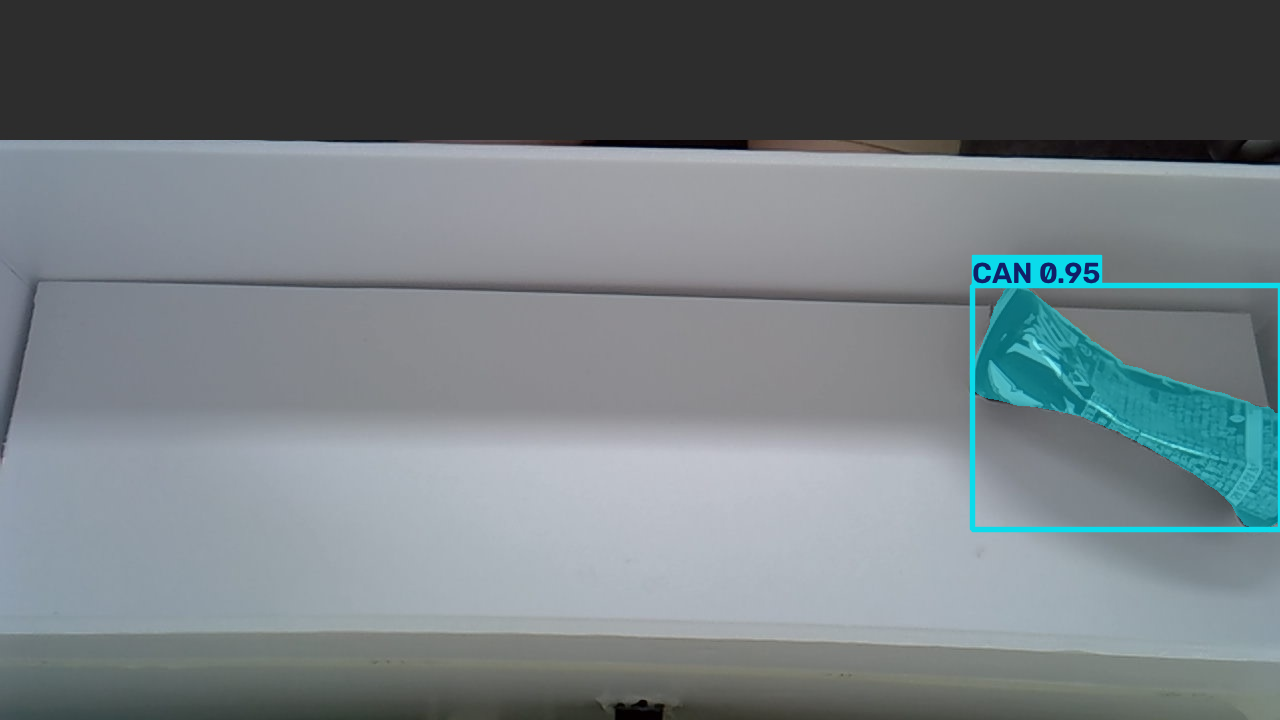

/content/recycle_seg_work/20260913_221430_265648/merged/images/val/old/can_20260910_101322_298_0010.jpg [('CAN', 0.96)]


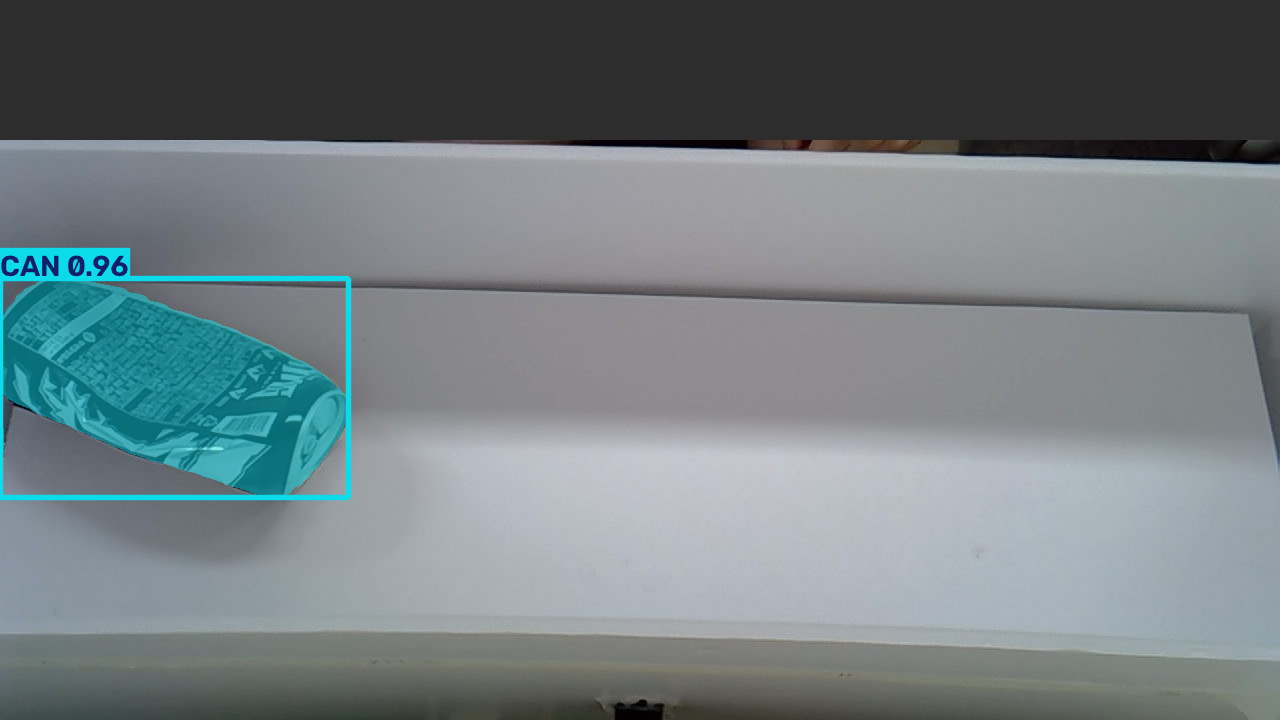

/content/recycle_seg_work/20260913_221430_265648/merged/images/val/old/can_20260910_101338_166_0015.jpg [('CAN', 0.961)]


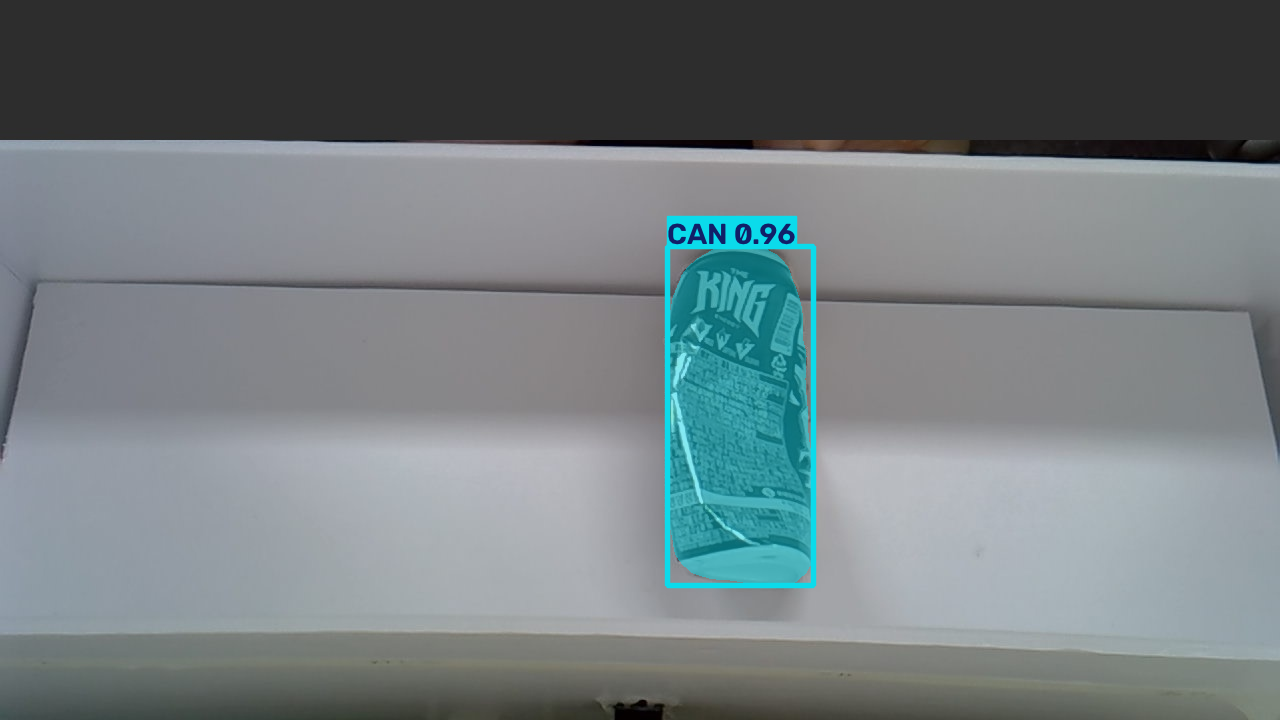

/content/recycle_seg_work/20260913_221430_265648/merged/images/val/old/can_20260910_101401_165_0020.jpg [('CAN', 0.952)]


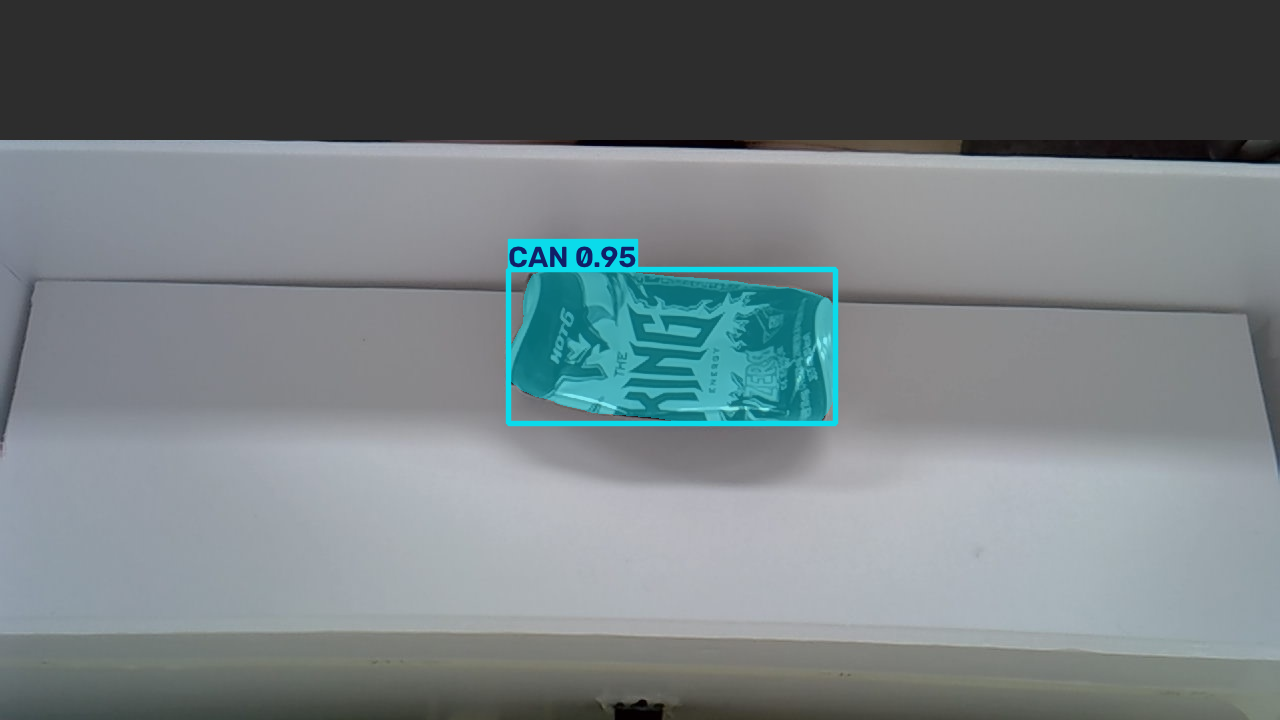

/content/recycle_seg_work/20260913_221430_265648/merged/images/val/old/can_20260910_101416_499_0025.jpg [('CAN', 0.966)]


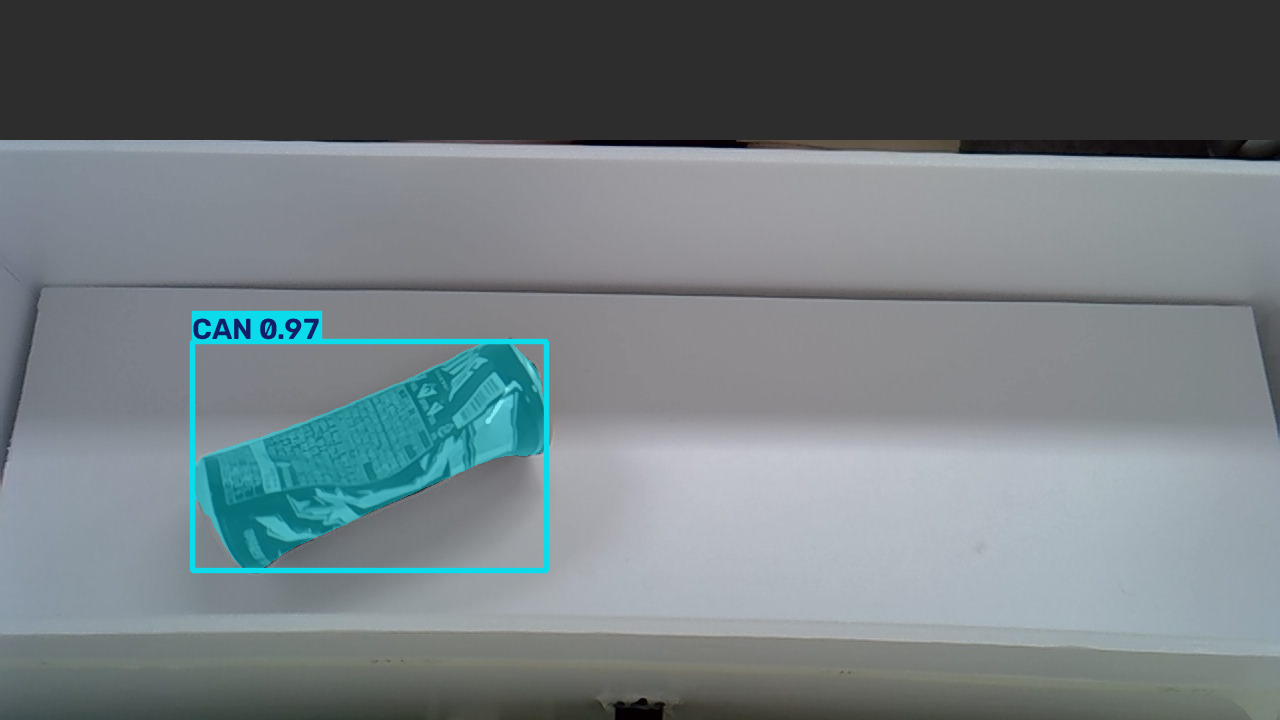

/content/recycle_seg_work/20260913_221430_265648/merged/images/val/old/can_20260910_101434_232_0030.jpg [('CAN', 0.969)]


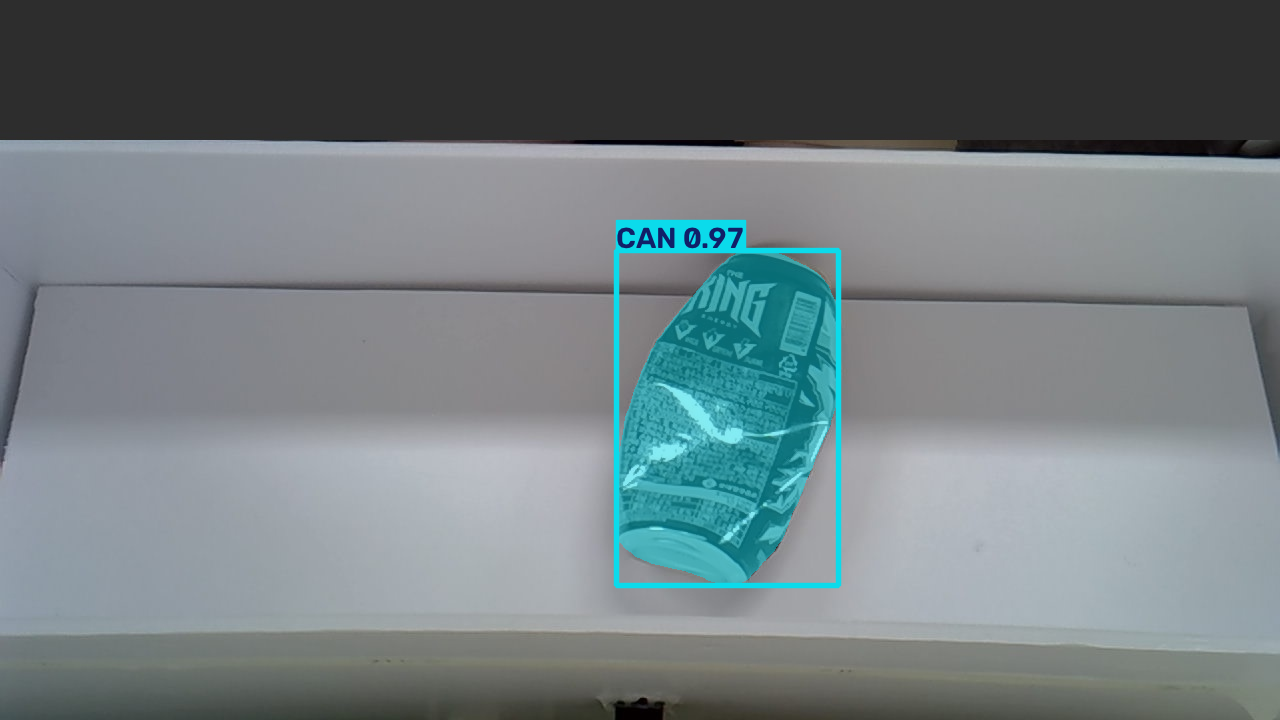

/content/recycle_seg_work/20260913_221430_265648/merged/images/val/old/can_20260910_101453_168_0035.jpg [('CAN', 0.973)]


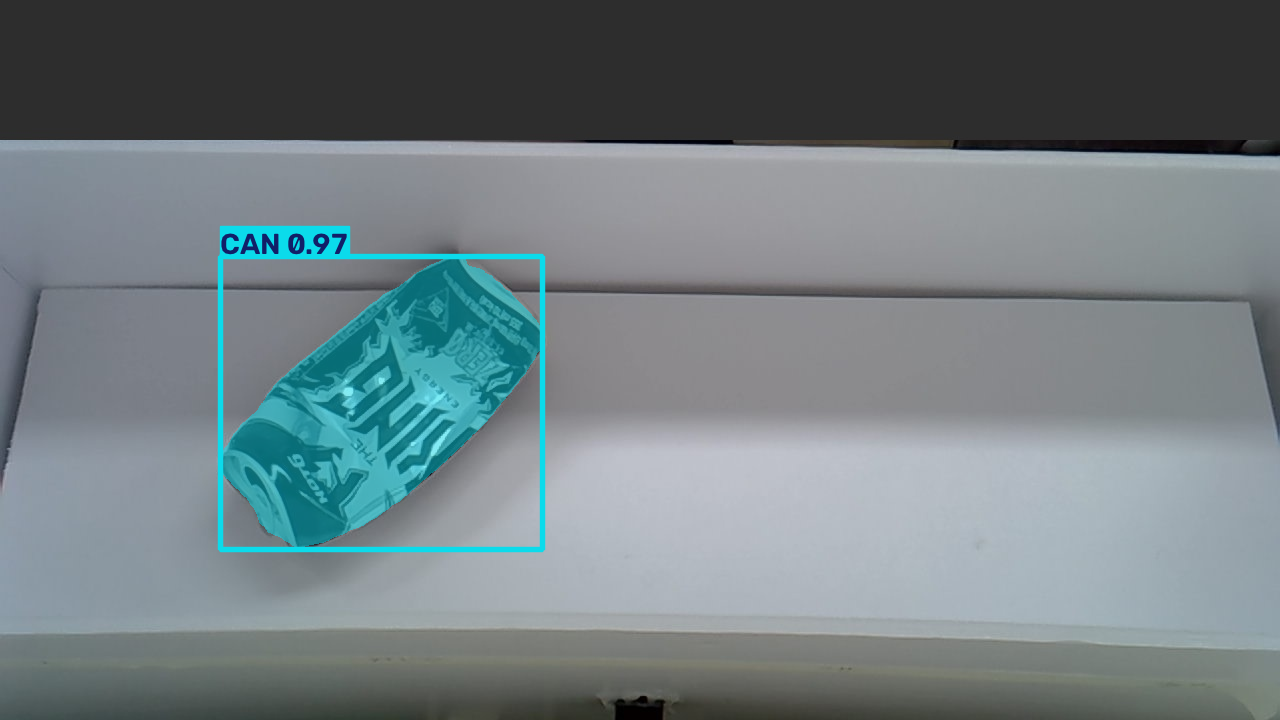

/content/recycle_seg_work/20260913_221430_265648/merged/images/val/old/can_20260910_101505_161_0040.jpg [('CAN', 0.964)]


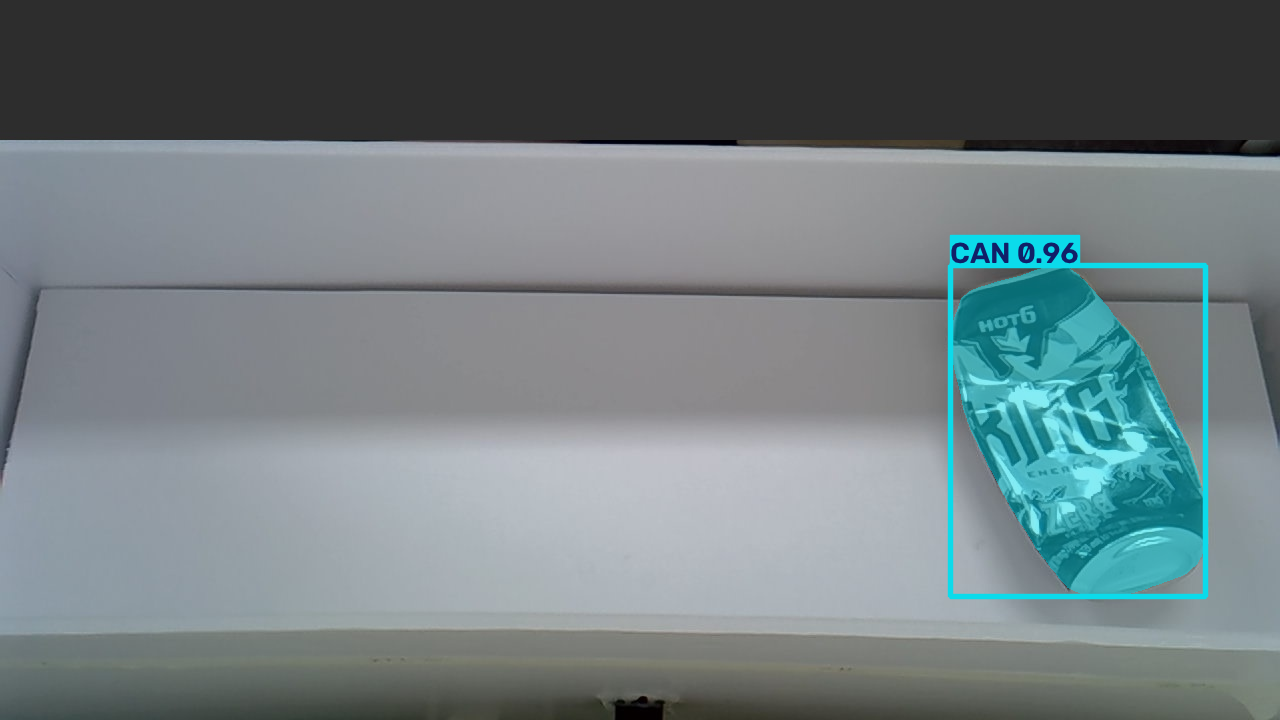

예측 저장: /content/drive/MyDrive/ai/final/model_seg/runs_seg/recycle_yolo11s-seg_20260913_221430_265648/predictions_023513_112422


In [ ]:
NEW_SOURCE=None  # 예: '/content/drive/MyDrive/recycle_new_photos'
PRED_DIR=RUN_DIR/('predictions_'+datetime.now().strftime('%H%M%S_%f'))
PRED_DIR.mkdir()
source=NEW_SOURCE if NEW_SOURCE is not None else [str(p) for p,_ in samples['val'][:8]]
for index,result in enumerate(yolo_best.predict(source=source,imgsz=DEPLOY_IMGSZ,
        conf=INFER_CONF,iou=0.7,device=DEVICE,retina_masks=True,stream=True,verbose=False)):
    stem=f'{index:06d}_{Path(result.path).stem}'
    canvas=Image.fromarray(result.plot()[...,::-1])
    canvas.save(PRED_DIR/f'{stem}_overlay.jpg')
    objects=[]
    if result.masks is not None:
        for j,(cls,conf,box,polygon,mask) in enumerate(zip(result.boxes.cls.cpu().tolist(),
            result.boxes.conf.cpu().tolist(),result.boxes.xyxy.cpu().tolist(),
            result.masks.xyn,result.masks.data.cpu().numpy())):
            mask_path=PRED_DIR/f'{stem}_object{j:03d}.png'
            Image.fromarray((mask>0.5).astype('uint8')*255).save(mask_path)
            objects.append(dict(instance=j,class_id=int(cls),class_name=result.names[int(cls)],
                confidence=float(conf),box_xyxy=box,polygon_normalized=polygon.tolist(),mask=mask_path.name))
    (PRED_DIR/f'{stem}.json').write_text(json.dumps(dict(image=result.path,
        status='detected' if objects else 'no_target_detected',objects=objects),
        ensure_ascii=False,indent=2),encoding='utf-8')
    print(result.path, [(x['class_name'],round(x['confidence'],3)) for x in objects])
    if index<8: display(canvas)
print('예측 저장:',PRED_DIR)

## 9. 학습 기록 저장 · ONNX
best.pt / last.pt는 RUN_DIR/weights에 있습니다. ONNX는 FP32 중간 파일입니다.
ONNX의 객체 출력만 처리하면 마스크를 잃습니다. 직접 구현 시 mask prototype/계수, NMS, 원본 좌표 복원을 함께 처리해야 합니다.
우선 Ultralytics predictor로 검증하세요. TensorRT 엔진 생성은 대상 Orin Nano에서 아래 별도 스크립트로 수행합니다.

In [ ]:
for name in ['manifest.json','dataset_counts.csv','duplicates_removed.csv','data.yaml']:
    shutil.copy2(DATASET_ROOT/name,REPORT_DIR/name)
actual_args=yaml.safe_load((RUN_DIR/'args.yaml').read_text(encoding='utf-8'))
(REPORT_DIR/'reproducibility.json').write_text(json.dumps(dict(
    ultralytics=ultralytics.__version__,torch=torch.__version__,cuda=torch.version.cuda,
    model=MODEL,sources=SOURCES,classes=CLASSES,train_args=actual_args,
    deploy_imgsz=DEPLOY_IMGSZ,infer_conf=INFER_CONF,
    note='PyTorch metrics only. TensorRT accuracy and end-to-end latency require target testing.'),
    ensure_ascii=False,indent=2,default=str),encoding='utf-8')
(REPORT_DIR/'pip_freeze.txt').write_text(subprocess.check_output(
    [sys.executable,'-m','pip','freeze'],text=True),encoding='utf-8')
if EXPORT_ONNX:
    exported=yolo_best.export(format='onnx',imgsz=DEPLOY_IMGSZ,batch=1,
        dynamic=False,half=False,simplify=False,opset=17,nms=False)
    print('ONNX:',exported)
print('best.pt:',BEST)
print('학습/평가 저장:',RUN_DIR)

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino

PyTorch: starting from '/content/drive/MyDrive/ai/final/model_seg/runs_seg/recycle_yolo11s-seg_20260913_221430_265648/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 40, 8400), (1, 32, 160, 160)) (19.6 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 5 packages in 324ms
Prepared 1 package in 771ms
Installed 1 package in 792ms
 + onnx==1.22.0

requirements: AutoUpdate success ✅ 2.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 17...
ONNX: export success